# Pandas — Complete Practical Notebook for Machine Learning

**A runnable, classroom-ready reference: common → advanced.** Covers practical Pandas operations used in the ML lifecycle: loading data, inspection, cleaning, transformation, EDA, combining data, time series, feature engineering, quality checks and train/test-ready tables.

Every topic includes **Why**, **Template code**, a **runnable example**, and an **interpretation or caution**. There are mini exercises, an answer key, and an end-to-end ML preparation workflow. The examples deliberately favor readable code over clever one-liners.

**Audience:** Beginner → intermediate ML students. **Dependencies:** `pandas`, `numpy`; `matplotlib` and `scikit-learn` for the last section; `openpyxl` for optional Excel examples. Designed for **pandas 2.2+ and 3.x**. The data is generated inside this notebook: no downloads, accounts or internet connection are required.

> Scope: This is a broad practical reference to **Pandas functions and methods relevant to ML**, not an encyclopedia of every internal Pandas API. Data preprocessing belongs in a fitted training pipeline when transformations are learned from data.

### Course map

1. Setup and reusable datasets
2. Creating Series / DataFrames
3. Loading and saving CSV, Excel, JSON, SQL and large files
4. Inspection and data profiling
5. Selecting and filtering rows / columns
6. Missing values, duplicates and type cleaning
7. String operations
8. Sorting, binning and ranking
9. Descriptive statistics and EDA
10. Grouping and aggregations
11. Joining / concatenating datasets
12. Reshaping and pivoting
13. Dates, time series and windows
14. Encoding and feature engineering
15. Data validation and efficient Pandas
16. Preparing ML train/test data without leakage
17. Classroom exercises and answer key
18. Function quick-reference and official resources

**How to use:** Run all cells top-to-bottom the first time. Examples create their own temporary variables so they don't unexpectedly alter the main demo table. `df` is the raw customer dataset; `orders` and `products` are related datasets.

## 1. Setup and datasets

We will use customers, their purchases, a product catalog and sample event logs. The intentionally imperfect values make cleaning examples meaningful.

In [1]:
# Uncomment this in a new environment if needed:
# %pip install -U pandas numpy matplotlib scikit-learn openpyxl
import pandas as pd
import numpy as np
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory

print('Pandas version:', pd.__version__)
print('NumPy version:', np.__version__)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 110)

Pandas version: 2.1.4
NumPy version: 1.26.4


In [2]:
# Customers: missing values, duplicate ID, inconsistent text and numeric strings.
df = pd.DataFrame({
    'customer_id': [101, 102, 103, 104, 105, 106, 107, 108, 109, 109, 110, 111],
    'name': [' Asha ', 'RAHUL', 'Nina', 'Dev', 'Sam', 'Mina', 'Tara', 'Amit', 'Noor', 'Noor', 'Ravi', 'Leela'],
    'city': ['Mumbai', 'delhi', 'Mumbai', 'Pune', None, 'Delhi', 'Bengaluru', 'pune', 'Mumbai', 'Mumbai', 'Pune', 'Delhi'],
    'age': ['25', '38', None, '42', 'not known', '30', '27', '35', '49', '49', '22', '31'],
    'income': [45000, 80000, 61000, np.nan, 50000, 72000, 55000, 68000, 92000, 92000, 36000, 64000],
    'plan': ['Basic', 'Premium', 'Basic', 'Premium', 'Basic', 'Gold', 'Gold', 'Basic', 'Premium', 'Premium', 'Gold', 'Basic'],
    'signup_date': ['2025-01-05', '2025-02-14', '2025-02-20', '2025-03-02', '2025-03-16', '2025-04-11', '2025-05-07', '2025-06-21', '2025-07-01', '2025-07-01', '2025-07-22', 'bad date'],
    'churned': [0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0]
})
orders = pd.DataFrame({
    'order_id': [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16],
    'customer_id': [101,101,102,103,104,105,105,106,107,108,108,109,110,111,101,106],
    'product_id': ['P1','P3','P2','P2','P1','P3','P2','P1','P4','P3','P1','P2','P4','P1','P2','P4'],
    'quantity': [1,2,1,1,3,1,2,1,2,1,1,2,1,2,1,2],
    'order_date': pd.to_datetime(['2025-07-01','2025-07-02','2025-07-03','2025-07-10','2025-07-15','2025-07-20','2025-07-22','2025-07-23','2025-08-01','2025-08-05','2025-08-06','2025-08-08','2025-08-10','2025-08-12','2025-09-01','2025-09-03'])
})
products = pd.DataFrame({
    'product_id': ['P1','P2','P3','P4'],
    'category': ['Electronics','Home','Electronics','Sports'],
    'unit_price': [1200,500,2200,750]
})
print('Customers:', df.shape, '| Orders:', orders.shape, '| Products:', products.shape)
display(df.head(4), orders.head(4), products)

Customers: (12, 8) | Orders: (16, 5) | Products: (4, 3)


,customer_id,name,city,age,income,plan,signup_date,churned
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0
2,103,Nina,Mumbai,None,61000.0,Basic,2025-02-20,1
3,104,Dev,Pune,42,NaN,Premium,2025-03-02,0


,order_id,customer_id,product_id,quantity,order_date
0,1,101,P1,1,2025-07-01
1,2,101,P3,2,2025-07-02
2,3,102,P2,1,2025-07-03
3,4,103,P2,1,2025-07-10


,product_id,category,unit_price
0,P1,Electronics,1200
1,P2,Home,500
2,P3,Electronics,2200
3,P4,Sports,750


## 2. Create and understand Pandas objects

A **Series** is a labeled 1-D array; a **DataFrame** is a labeled 2-D table. Index labels affect alignment.

### pd.Series()

**Why for ML:** Represent one feature or target vector.

**Template:** `pd.Series(data, name="feature")`

**How to interpret:** `Series` has an index (0, 1, 2) and one name.

In [3]:
scores = pd.Series([76, 82, 91], name='score')
print(scores)
print('Mean score:', scores.mean())

0    76
1    82
2    91
Name: score, dtype: int64
Mean score: 83.0


### pd.DataFrame()

**Why for ML:** Build a table for model input or experimentation.

**Template:** `pd.DataFrame({"col": values})`

In [4]:
students = pd.DataFrame({'student': ['A', 'B', 'C'], 'marks': [85, 60, 92]})
display(students)

,student,marks
0,A,85
1,B,60
2,C,92


### DataFrame.from_records() / to_dict()

**Why for ML:** Convert rows from APIs or dictionaries into a table and back.

**Template:** `pd.DataFrame.from_records(records)`

In [4]:
records = [{'id': 1, 'value': 10}, {'id': 2, 'value': 20}]
records_df = pd.DataFrame.from_records(records)
print(records_df.to_dict(orient='records'))

[{'id': 1, 'value': 10}, {'id': 2, 'value': 20}]


**Adding column name to DF**

In [6]:
records_df.columns = ['CustomerId','Account']
display(records_df)

,CustomerId,Account
0,1,10
1,2,20


### copy()

**Why for ML:** Safely experiment without changing the original table.

**Template:** `working = df.copy()`

**How to interpret:** Works consistently in pandas 2.2+; pandas 3 uses Copy-on-Write semantics.

In [7]:
working = df.copy()
working.loc[0, 'name'] = 'New Name'
print('Original:', df.loc[0, 'name'], '| Copy:', working.loc[0, 'name'])

Original:  Asha  | Copy: New Name


### index / columns / axes

**Why for ML:** Understand row labels and feature names.

**Template:** `df.index; df.columns`

In [7]:
print('Index:', df.index)
print('Columns:', list(df.columns))
print('Number of dimensions:', df.ndim)

Index: RangeIndex(start=0, stop=12, step=1)
Columns: ['customer_id', 'name', 'city', 'age', 'income', 'plan', 'signup_date', 'churned']
Number of dimensions: 2


## 3. Load and save data

Most real ML pipelines start by reading a data file or a database query. Pandas supports many formats; these demonstrations use temporary, local files.

### to_csv() / read_csv()

**Why for ML:** Store and load standard tabular ML datasets.

**Template:** `df.to_csv(path, index=False); pd.read_csv(path)`

**How to interpret:** `index=False` prevents a needless saved index column.

In [8]:
with TemporaryDirectory() as folder:
    path = Path(folder) / 'customers.csv'
    df.to_csv(path, index=False)
    loaded = pd.read_csv(path)
    display(loaded.head(3))

,customer_id,name,city,age,income,plan,signup_date,churned
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0
2,103,Nina,Mumbai,NaN,61000.0,Basic,2025-02-20,1


### read_csv(usecols=, dtype=, na_values=)

**Why for ML:** Control import, prevent ID corruption and mark custom missing text.

**Template:** `pd.read_csv(path, usecols=[...], dtype={...}, na_values=[...])`

**How to interpret:** Keeping IDs as text preserves leading zeros.

In [9]:
csv_text = 'id,age,city\n001,28,Mumbai\n002,Unknown,Pune\n003,36,Delhi'
loaded = pd.read_csv(StringIO(csv_text), usecols=['id','age','city'],
                     dtype={'id': 'string'}, na_values=['Unknown'])
print(loaded.dtypes)
display(loaded)

id      string[python]
age            float64
city            object
dtype: object


,id,age,city
0,001,28.0,Mumbai
1,002,NaN,Pune
2,003,36.0,Delhi


### read_csv(parse_dates=, nrows=)

**Why for ML:** Parse temporal data and preview large files.

**Template:** `pd.read_csv(path, parse_dates=["date"], nrows=100)`

In [10]:
csv_text = 'event_date,sales\n2025-01-01,100\n2025-01-02,200\n2025-01-03,300'
preview = pd.read_csv(StringIO(csv_text), parse_dates=['event_date'], nrows=2)
print(preview.dtypes)
display(preview)

event_date    datetime64[ns]
sales                  int64
dtype: object


,event_date,sales
0,2025-01-01,100
1,2025-01-02,200


### read_csv(chunksize=)

**Why for ML:** Process large files in manageable batches.

**Template:** `for chunk in pd.read_csv(path, chunksize=10000): ...`

**How to interpret:** Do not compute a global average by averaging unweighted chunk averages.

In [11]:
csv_text = 'a,b\n1,10\n2,20\n3,30\n4,40\n5,50'
total = 0
for chunk in pd.read_csv(StringIO(csv_text), chunksize=2):
    total += chunk['b'].sum()
print('Chunked sum:', total)

Chunked sum: 150


### to_excel() / read_excel()

**Why for ML:** Exchange tabular data with students or analysts using Excel.

**Template:** `df.to_excel(path, index=False); pd.read_excel(path)`

In [12]:
try:
    import openpyxl
    with TemporaryDirectory() as folder:
        path = Path(folder) / 'customers.xlsx'
        df.to_excel(path, sheet_name='Customers', index=False)
        excel_df = pd.read_excel(path, sheet_name='Customers')
        display(excel_df.head(2))
except ImportError:
    print('Optional: install openpyxl to run Excel examples.')

,customer_id,name,city,age,income,plan,signup_date,churned
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0


### to_json() / read_json()

**Why for ML:** Move data between APIs and Python tables.

**Template:** `df.to_json(orient="records"); pd.read_json(StringIO(text), orient="records")`

In [13]:
json_text = students.to_json(orient='records')
json_df = pd.read_json(StringIO(json_text), orient='records')
display(json_df)

,student,marks
0,A,85
1,B,60
2,C,92


### read_sql_query() / to_sql()

**Why for ML:** Use database tables without manually parsing SQL rows.

**Template:** `pd.read_sql_query(query, connection)`

**How to interpret:** Use parameterized SQL queries when accepting user input.

In [14]:
import sqlite3
with sqlite3.connect(':memory:') as conn:
    products.to_sql('products', conn, index=False, if_exists='replace')
    sql_df = pd.read_sql_query('SELECT * FROM products WHERE unit_price >= 750', conn)
display(sql_df)

,product_id,category,unit_price
0,P1,Electronics,1200
1,P3,Electronics,2200
2,P4,Sports,750


### read_parquet() / to_parquet() [optional]

**Why for ML:** Parquet is columnar, compact and common in large ML workflows.

**Template:** `df.to_parquet(path); pd.read_parquet(path)`

In [15]:
try:
    import pyarrow
    with TemporaryDirectory() as folder:
        path = Path(folder) / 'orders.parquet'
        orders.to_parquet(path, index=False)
        pq_df = pd.read_parquet(path)
        display(pq_df.head(2))
except ImportError:
    print('Optional: install pyarrow to run Parquet examples.')

Optional: install pyarrow to run Parquet examples.


## 4. Inspect and profile data

Before modelling, determine shape, types, target distribution, missing values and duplicate risk.

### head() / tail() / sample()

**Why for ML:** Quickly inspect the beginning, end or random rows.

**Template:** `df.head(5); df.tail(5); df.sample(5, random_state=42)`

**How to interpret:** Use `random_state` for repeatable teaching examples.

In [16]:
display(df.head(3))
display(df.tail(2))
display(df.sample(3, random_state=42))

,customer_id,name,city,age,income,plan,signup_date,churned
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0
2,103,Nina,Mumbai,None,61000.0,Basic,2025-02-20,1


,customer_id,name,city,age,income,plan,signup_date,churned
10,110,Ravi,Pune,22,36000.0,Gold,2025-07-22,1
11,111,Leela,Delhi,31,64000.0,Basic,bad date,0


,customer_id,name,city,age,income,plan,signup_date,churned
10,110,Ravi,Pune,22,36000.0,Gold,2025-07-22,1
9,109,Noor,Mumbai,49,92000.0,Premium,2025-07-01,0
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0


### shape / size / empty

**Why for ML:** Establish row and feature counts.

**Template:** `df.shape; df.size; df.empty`

In [17]:
print('Rows, columns:', df.shape)
print('All cells:', df.size)
print('Has no rows?', df.empty)

Rows, columns: (12, 8)
All cells: 96
Has no rows? False


### dtypes / info()

**Why for ML:** Spot strings stored as numbers and inappropriate feature types.

**Template:** `df.dtypes; df.info()`

**How to interpret:** Here, `age` is text because some entries are not valid numbers.

In [18]:
print(df.dtypes)
df.info()

customer_id      int64
name            object
city            object
age             object
income         float64
plan            object
signup_date     object
churned          int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_id  12 non-null     int64  
 1   name         12 non-null     object 
 2   city         11 non-null     object 
 3   age          11 non-null     object 
 4   income       11 non-null     float64
 5   plan         12 non-null     object 
 6   signup_date  12 non-null     object 
 7   churned      12 non-null     int64  
dtypes: float64(1), int64(2), object(5)
memory usage: 900.0+ bytes


### describe() / describe(include="all")

**Why for ML:** Summarize central tendency, spread and categorical frequencies.

**Template:** `df.describe(); df.describe(include="all")`

In [19]:
display(df.select_dtypes(include='number').describe())
display(df[['city','plan']].describe(include='all'))

,customer_id,income,churned
count,12.000000,11.00000,12.000000
mean,106.250000,65000.00000,0.333333
std,3.278719,18231.84028,0.492366
min,101.000000,36000.00000,0.000000
25%,103.750000,52500.00000,0.000000
50%,106.500000,64000.00000,0.000000
75%,109.000000,76000.00000,1.000000
max,111.000000,92000.00000,1.000000


,city,plan
count,11,12
unique,6,3
top,Mumbai,Basic
freq,4,5


### select_dtypes()

**Why for ML:** Separate numeric, categorical and datetime features reliably.

**Template:** `df.select_dtypes(include="number")`

**How to interpret:** Pandas 3 infers new `str` dtype for text; avoid assuming all text is `object`.

In [20]:
num_cols = df.select_dtypes(include='number').columns.tolist()
text_cols = df.select_dtypes(include=['object','string']).columns.tolist()
print('Numeric:', num_cols)
print('Text:', text_cols)

Numeric: ['customer_id', 'income', 'churned']
Text: ['name', 'city', 'age', 'plan', 'signup_date']


### nunique() / unique()

**Why for ML:** Discover the number and identities of category values.

**Template:** `df["col"].nunique(); df["col"].unique()`

In [21]:
print('Distinct plans:', df['plan'].nunique())
print('City values:', df['city'].unique())

Distinct plans: 3
City values: ['Mumbai' 'delhi' 'Pune' None 'Delhi' 'Bengaluru' 'pune']


### value_counts() / normalize=True

**Why for ML:** Check class balance, frequency and rare categories.

**Template:** `df["target"].value_counts(normalize=True)`

**How to interpret:** Important before choosing accuracy or other model metrics.

In [22]:
print('Target counts:')
print(df['churned'].value_counts())
print('Target proportions:')
print(df['churned'].value_counts(normalize=True).round(3))

Target counts:
churned
0    8
1    4
Name: count, dtype: int64
Target proportions:
churned
0    0.667
1    0.333
Name: proportion, dtype: float64


### isna() / notna() / sum()

**Why for ML:** Quantify missingness by column and across rows.

**Template:** `df.isna().sum(); df.notna().sum()`

In [23]:
missing = df.isna().sum().sort_values(ascending=False)
print('Missing per column:')
print(missing)
print('Missing rate (%):')
print((df.isna().mean() * 100).round(1))

Missing per column:
age            1
city           1
income         1
name           0
customer_id    0
plan           0
signup_date    0
churned        0
dtype: int64
Missing rate (%):
customer_id    0.0
name           0.0
city           8.3
age            8.3
income         8.3
plan           0.0
signup_date    0.0
churned        0.0
dtype: float64


### duplicated()

**Why for ML:** Find repeated keys and records before merging.

**Template:** `df.duplicated(subset=["id"], keep=False)`

**How to interpret:** A duplicate customer ID can create extra rows after a merge.

In [24]:
display(df.loc[df.duplicated(subset=['customer_id'], keep=False)])
print('Exact duplicate rows:', df.duplicated().sum())

,customer_id,name,city,age,income,plan,signup_date,churned
8,109,Noor,Mumbai,49,92000.0,Premium,2025-07-01,0
9,109,Noor,Mumbai,49,92000.0,Premium,2025-07-01,0


Exact duplicate rows: 1


### memory_usage()

**Why for ML:** Understand memory pressure on wider ML datasets.

**Template:** `df.memory_usage(deep=True)`

In [25]:
print(df.memory_usage(deep=True))
print('Total KiB:', round(df.memory_usage(deep=True).sum() / 1024, 2))

Index          132
customer_id     96
name           638
city           623
age            592
income          96
plan           653
signup_date    706
churned         96
dtype: int64
Total KiB: 3.55


## 5. Select, filter and modify safely

Use explicit column names and boolean conditions; `.loc` is safer than chained assignment.

### Single and multiple column selection

**Why for ML:** Create feature matrices without the target.

**Template:** `df["age"]; df[["age","income"]]`

In [26]:
display(df['income'].head())
display(df[['customer_id','income','plan']].head())

0    45000.0
1    80000.0
2    61000.0
3        NaN
4    50000.0
Name: income, dtype: float64

,customer_id,income,plan
0,101,45000.0,Basic
1,102,80000.0,Premium
2,103,61000.0,Basic
3,104,NaN,Premium
4,105,50000.0,Basic


### loc[] — label-based selection

**Why for ML:** Select rows / columns by label and perform reliable assignment.

**Template:** `df.loc[condition, ["a","b"]]`

**How to interpret:** Never rely on `df[mask]["col"] = value`; use `df.loc[mask, "col"] = value`.

In [27]:
display(df.loc[df['income'] > 65000, ['customer_id','income']])
local = df.copy()
local.loc[local['income'] > 80000, 'high_income'] = 1
local['high_income'] = local['high_income'].fillna(0).astype(int)
display(local[['income','high_income']].head())

,customer_id,income
1,102,80000.0
5,106,72000.0
7,108,68000.0
8,109,92000.0
9,109,92000.0


,income,high_income
0,45000.0,0
1,80000.0,0
2,61000.0,0
3,NaN,0
4,50000.0,0


### iloc[] — position-based selection

**Why for ML:** Select rows or columns by numeric position.

**Template:** `df.iloc[:5, :3]`

In [28]:
display(df.iloc[:4, :3])
print('First row, first value:', df.iloc[0, 0])

,customer_id,name,city
0,101,Asha,Mumbai
1,102,RAHUL,delhi
2,103,Nina,Mumbai
3,104,Dev,Pune


First row, first value: 101


### at[] / iat[] — scalar access

**Why for ML:** Read one value explicitly; useful for debugging.

**Template:** `df.at[row_label, "col"]; df.iat[row_pos, col_pos]`

In [29]:
print(df.at[0, 'name'])
print(df.iat[0, 0])

 Asha 
101


### Boolean masks: &, | and ~

**Why for ML:** Filter with multiple conditions.

**Template:** `df[(condition1) & (condition2)]`

**How to interpret:** Use parentheses around each condition and `&`, `|`, `~` rather than Python `and`, `or`, `not`.

In [30]:
selected = df[(df['income'] > 60000) & (df['plan'] == 'Premium')]
display(selected[['customer_id','income','plan']])
print('Not Premium:', (~df['plan'].eq('Premium')).sum())

,customer_id,income,plan
1,102,80000.0,Premium
8,109,92000.0,Premium
9,109,92000.0,Premium


Not Premium: 8


### isin() / between()

**Why for ML:** Filter a known set or a closed numeric interval.

**Template:** `df["col"].isin(values); df["x"].between(a, b)`

In [31]:
display(df.loc[df['plan'].isin(['Gold','Premium']), ['customer_id','plan']].head())
display(df.loc[df['income'].between(50000, 75000), ['customer_id','income']])

,customer_id,plan
1,102,Premium
3,104,Premium
5,106,Gold
6,107,Gold
8,109,Premium


,customer_id,income
2,103,61000.0
4,105,50000.0
5,106,72000.0
6,107,55000.0
7,108,68000.0
11,111,64000.0


### query()

**Why for ML:** Express simple row filtering compactly.

**Template:** `df.query("income > @threshold")`

**How to interpret:** Avoid building query expressions from untrusted text.

In [32]:
threshold = 60000
display(df.query('income > @threshold and plan == "Basic"')[['customer_id','income','plan']])

,customer_id,income,plan
2,103,61000.0,Basic
7,108,68000.0,Basic
11,111,64000.0,Basic


### filter() / get()

**Why for ML:** Pick columns by name pattern or safely request an optional column.

**Template:** `df.filter(like="date"); df.get("name", default)`

In [33]:
print('Date-like columns:', df.filter(like='date').columns.tolist())
print('Optional column:', df.get('unavailable_column', 'not present'))

Date-like columns: ['signup_date']
Optional column: not present


### rename() / drop()

**Why for ML:** Make feature names consistent and remove unwanted fields.

**Template:** `df.rename(columns={...}); df.drop(columns=[...])`

In [34]:
tidy = df.rename(columns={'income':'annual_income'}).drop(columns=['name'])
display(tidy.head(2))

,customer_id,city,age,annual_income,plan,signup_date,churned
0,101,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,delhi,38,80000.0,Premium,2025-02-14,0


### set_index() / reset_index()

**Why for ML:** Choose row labels for joins and alignment, then restore columns.

**Template:** `df.set_index("customer_id").reset_index()`

**How to interpret:** An index is not automatically an ML feature.

In [35]:
indexed = df.drop_duplicates('customer_id').set_index('customer_id')
print(indexed.loc[101, 'plan'])
display(indexed.reset_index().head(2))

Basic


,customer_id,name,city,age,income,plan,signup_date,churned
0,101,Asha,Mumbai,25,45000.0,Basic,2025-01-05,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0


### where() / mask()

**Why for ML:** Keep valid values or replace invalid entries conditionally.

**Template:** `s.where(condition, other); s.mask(condition, other)`

In [36]:
income = df['income']
print('where:', income.where(income >= 60000, other=0).head().tolist())
print('mask:', income.mask(income > 90000, other=90000).head(10).tolist())

where: [0.0, 80000.0, 61000.0, 0.0, 0.0]
mask: [45000.0, 80000.0, 61000.0, nan, 50000.0, 72000.0, 55000.0, 68000.0, 90000.0, 90000.0]


## 6. Clean messy data

Cleaning decisions must respect business logic and train/test boundaries. The dataset intentionally contains bad dates and ages, inconsistent city text, and missing income.

### to_numeric(errors="coerce")

**Why for ML:** Turn numeric-looking strings into numbers; treat invalid entries as missing.

**Template:** `pd.to_numeric(df["age"], errors="coerce")`

**How to interpret:** `errors="coerce"` turns `not known` into NaN rather than crashing.

In [37]:
clean = df.drop_duplicates('customer_id').copy()
clean['age'] = pd.to_numeric(clean['age'], errors='coerce')
print(clean[['customer_id','age']].head(7))

   customer_id   age
0          101  25.0
1          102  38.0
2          103   NaN
3          104  42.0
4          105   NaN
5          106  30.0
6          107  27.0


### to_datetime(errors="coerce")

**Why for ML:** Convert event/sign-up dates and identify invalid dates.

**Template:** `pd.to_datetime(s, errors="coerce")`

In [38]:
clean['signup_date'] = pd.to_datetime(clean['signup_date'], errors='coerce')
print(clean[['customer_id','signup_date']].tail(3))

    customer_id signup_date
8           109  2025-07-01
10          110  2025-07-22
11          111         NaT


### astype() / convert_dtypes()

**Why for ML:** Control numerical and nullable types to avoid incorrect calculations.

**Template:** `df.astype({"age":"Int64"}); df.convert_dtypes()`

**How to interpret:** Use nullable `Int64` (capital I) when integer ages can contain missing values.

In [39]:
ages = pd.to_numeric(df['age'], errors='coerce').astype('Int64')
print('Nullable integer age:')
print(ages.head(7))
print('Convert dtypes:\n', df[['customer_id','name']].convert_dtypes().dtypes)

Nullable integer age:
0      25
1      38
2    <NA>
3      42
4    <NA>
5      30
6      27
Name: age, dtype: Int64
Convert dtypes:
 customer_id             Int64
name           string[python]
dtype: object


### fillna() — fixed / median / mode

**Why for ML:** Make missing values explicit; choose an imputation strategy.

**Template:** `s.fillna(s.median()); s.fillna(s.mode().iloc[0])`

**How to interpret:** Learn imputation statistics **only on the training split**, not the full dataset.

In [40]:
clean['age_filled'] = clean['age'].fillna(clean['age'].median())
clean['city_filled'] = clean['city'].fillna(clean['city'].mode().iloc[0])
print(clean[['age','age_filled','city','city_filled']].head(7))

    age  age_filled       city city_filled
0  25.0        25.0     Mumbai      Mumbai
1  38.0        38.0      delhi       delhi
2   NaN        31.0     Mumbai      Mumbai
3  42.0        42.0       Pune        Pune
4   NaN        31.0       None      Mumbai
5  30.0        30.0      Delhi       Delhi
6  27.0        27.0  Bengaluru   Bengaluru


### groupby().transform() — group median fill

**Why for ML:** Impute missing data using a meaningful group, preserving original row count.

**Template:** `s.fillna(df.groupby("group")["value"].transform("median"))`

**How to interpret:** Avoid group-derived statistics from validation/test examples when building a deployed pipeline.

In [41]:
demo = pd.DataFrame({'region':['A','A','B','B'], 'spend':[10, np.nan, 80, np.nan]})
demo['spend_filled'] = demo['spend'].fillna(demo.groupby('region')['spend'].transform('median'))
display(demo)

,region,spend,spend_filled
0,A,10.0,10.0
1,A,NaN,10.0
2,B,80.0,80.0
3,B,NaN,80.0


### dropna()

**Why for ML:** Discard rows only when dropping does not bias the sample.

**Template:** `df.dropna(subset=["important_col"])`

**How to interpret:** Dropping all rows with any missing value can cause substantial data loss.

In [42]:
print('Original:', len(df))
print('After required income:', len(df.dropna(subset=['income'])))
print('After any NA in all columns:', len(df.dropna()))

Original: 12
After required income: 11
After any NA in all columns: 9


### drop_duplicates()

**Why for ML:** Prevent double-counting customers or repeated transactions.

**Template:** `df.drop_duplicates(subset=["id"], keep="first")`

**How to interpret:** Define the real business key before deduplicating.

In [43]:
unique_customers = df.drop_duplicates(subset=['customer_id'], keep='first')
print('Before:', len(df), '| After:', len(unique_customers))

Before: 12 | After: 11


### replace()

**Why for ML:** Standardize inconsistent category codes or sentinel values.

**Template:** `s.replace({"OLD":"NEW"})`

In [44]:
cities = df['city'].replace({'delhi':'Delhi', 'pune':'Pune'})
print(cities.value_counts(dropna=False))

city
Mumbai       4
Delhi        3
Pune         3
None         1
Bengaluru    1
Name: count, dtype: int64


### combine_first()

**Why for ML:** Fill missing entries in one column from another fallback column.

**Template:** `primary.combine_first(fallback)`

In [45]:
contact = pd.DataFrame({'email': [None,'a@x.com',None], 'backup':['a@backup.com',None,'c@x.com']})
contact['preferred_email'] = contact['email'].combine_first(contact['backup'])
display(contact)

,email,backup,preferred_email
0,None,a@backup.com,a@backup.com
1,a@x.com,None,a@x.com
2,None,c@x.com,c@x.com


### isna().astype(int) — missing indicator

**Why for ML:** Sometimes missingness itself predicts an outcome.

**Template:** `df["missing_flag"] = df["x"].isna().astype(int)`

**How to interpret:** For proper ML, learn on training and apply exactly the same columns at inference.

In [46]:
clean['income_missing'] = clean['income'].isna().astype(int)
print(clean[['customer_id','income','income_missing']].head())

   customer_id   income  income_missing
0          101  45000.0               0
1          102  80000.0               0
2          103  61000.0               0
3          104      NaN               1
4          105  50000.0               0


### clip()

**Why for ML:** Cap values outside chosen lower/upper bounds.

**Template:** `df["x"].clip(lower=a, upper=b)`

**How to interpret:** Do not automatically clip genuine extreme cases; validate domain rules.

In [47]:
values = pd.Series([100, 120, 130, 160, 1500])
print('Raw:', values.tolist())
print('Clipped:', values.clip(upper=200).tolist())

Raw: [100, 120, 130, 160, 1500]
Clipped: [100, 120, 130, 160, 200]


### quantile() / IQR diagnostics

**Why for ML:** Find potential extreme values using quartiles.

**Template:** `q1=s.quantile(.25); q3=s.quantile(.75)`

**How to interpret:** IQR flags candidates, not necessarily data errors.

In [48]:
income = df['income'].dropna()
q1, q3 = income.quantile(0.25), income.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f'Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, bounds=({lower:.1f}, {upper:.1f})')
print('Potential outliers:', income[(income < lower) | (income > upper)].tolist())

Q1=52500.0, Q3=76000.0, IQR=23500.0, bounds=(17250.0, 111250.0)
Potential outliers: []


## 7. Text and categorical strings

Pandas string functions are vectorized through `.str`. Normalize text before counting or encoding categories.

### str.strip() / lower() / upper() / title()

**Why for ML:** Standardize free-text categories and names.

**Template:** `s.str.strip().str.title()`

In [49]:
city_clean = df['city'].astype('string').str.strip().str.title()
name_clean = df['name'].str.strip().str.title()
print(city_clean.value_counts(dropna=False))
print('Names:', name_clean.head(4).tolist())

city
Mumbai       4
Delhi        3
Pune         3
<NA>         1
Bengaluru    1
Name: count, dtype: Int64
Names: ['Asha', 'Rahul', 'Nina', 'Dev']


### str.contains() / startswith() / endswith()

**Why for ML:** Create text-based flags and filters.

**Template:** `s.str.contains("pattern", case=False, na=False)`

**How to interpret:** Regular expressions are the default for `contains`; set `regex=False` for literal text.

In [50]:
names = df['name'].astype('string').str.strip()
print('Contains a:', names.str.contains('a', case=False, na=False).tolist())
print('Starts with R:', names.str.startswith('R', na=False).sum())
print('Ends with a:', names.str.lower().str.endswith('a', na=False).sum())

Contains a: [True, True, True, False, True, True, True, True, False, False, True, True]
Starts with R: 2
Ends with a: 5


### str.replace()

**Why for ML:** Remove unwanted characters or standardize text.

**Template:** `s.str.replace(pattern, replacement, regex=True)`

In [51]:
phones = pd.Series(['+91-9876 543210', '98765-43210'])
print(phones.str.replace(r'[^0-9]', '', regex=True).tolist())

['919876543210', '9876543210']


### str.split() / str.get()

**Why for ML:** Extract components of structured text.

**Template:** `s.str.split("@", expand=True)`

In [52]:
emails = pd.Series(['asha@example.com','dev@company.org'])
parts = emails.str.split('@', expand=True)
parts.columns = ['user','domain']
display(parts)
print('Top-level domains:', emails.str.split('.').str.get(-1).tolist())

,user,domain
0,asha,example.com
1,dev,company.org


Top-level domains: ['com', 'org']


### str.extract()

**Why for ML:** Extract a matched pattern into a feature.

**Template:** `s.str.extract(r"(pattern)")`

**How to interpret:** Non-matches become missing values.

In [53]:
codes = pd.Series(['ORD-1001','ORD-2002','INVALID'])
print(codes.str.extract(r'ORD-(\d+)', expand=False))

0    1001
1    2002
2     NaN
dtype: object


### str.len() / str.count()

**Why for ML:** Create simple character-count or token-count features.

**Template:** `s.str.len(); s.str.count(" ")`

In [54]:
reviews = pd.Series(['very good', 'good', 'not good at all'])
print('Length:', reviews.str.len().tolist())
print("Occurrences of 'good':", reviews.str.count('good').tolist())

Length: [9, 4, 15]
Occurrences of 'good': [1, 1, 1]


### str.get_dummies()

**Why for ML:** Make binary flags from separator-delimited tags.

**Template:** `s.str.get_dummies(sep="|")`

**How to interpret:** Multi-label tags are different from a single-category one-hot feature.

In [55]:
tags = pd.Series(['sports|travel','travel','sports|music'])
display(tags.str.get_dummies(sep='|'))

,music,sports,travel
0,0,1,1
1,0,0,1
2,1,1,0


## 8. Sort, rank, bin and compare

These methods are useful for EDA, feature transformation, business scoring and sequence features.

### sort_values() / sort_index()

**Why for ML:** Order samples for analysis; time series must be sorted for shifts.

**Template:** `df.sort_values("column", ascending=False)`

In [56]:
display(df.sort_values(['income','customer_id'], ascending=[False,True]).head(4))
print('Index after sort:', df.sort_values('income').sort_index().index[:5].tolist())

,customer_id,name,city,age,income,plan,signup_date,churned
8,109,Noor,Mumbai,49,92000.0,Premium,2025-07-01,0
9,109,Noor,Mumbai,49,92000.0,Premium,2025-07-01,0
1,102,RAHUL,delhi,38,80000.0,Premium,2025-02-14,0
5,106,Mina,Delhi,30,72000.0,Gold,2025-04-11,0


Index after sort: [0, 1, 2, 3, 4]


### nlargest() / nsmallest()

**Why for ML:** Find top and bottom cases efficiently.

**Template:** `df.nlargest(5, "income")`

In [57]:
display(df.nlargest(3, 'income')[['customer_id','income']])
display(df.nsmallest(3, 'income')[['customer_id','income']])

,customer_id,income
8,109,92000.0
9,109,92000.0
1,102,80000.0


,customer_id,income
10,110,36000.0
0,101,45000.0
4,105,50000.0


### rank()

**Why for ML:** Convert values into ranked features.

**Template:** `df["x"].rank(ascending=False, method="dense")`

**How to interpret:** Ties can be handled with `average`, `min`, `max`, `dense` or `first`.

In [58]:
values = pd.Series([90, 70, 90, 55])
print('Ranks:', values.rank(ascending=False, method='dense').tolist())

Ranks: [1.0, 2.0, 1.0, 3.0]


### round() / abs()

**Why for ML:** Control presentation and magnitude of deviations.

**Template:** `s.round(2); s.abs()`

In [59]:
errors = pd.Series([-2.555, 0.011, 3.444])
print('Rounded:', errors.round(2).tolist())
print('Absolute:', errors.abs().tolist())

Rounded: [-2.56, 0.01, 3.44]
Absolute: [2.555, 0.011, 3.444]


### pd.cut()

**Why for ML:** Convert a numeric range into interpretable fixed bins.

**Template:** `pd.cut(s, bins=[...], labels=[...])`

**How to interpret:** Define boundaries based on the task or training data.

In [60]:
ages = pd.Series([17, 24, 35, 61, 82])
groups = pd.cut(ages, bins=[0, 18, 35, 60, np.inf], labels=['Child','Young','Adult','Senior'])
print(pd.DataFrame({'age': ages, 'group': groups}))

   age   group
0   17   Child
1   24   Young
2   35   Young
3   61  Senior
4   82  Senior


### pd.qcut()

**Why for ML:** Create approximately equally populated quantile bins.

**Template:** `pd.qcut(s, q=4, duplicates="drop")`

**How to interpret:** Bin edges learned from the complete dataset can leak validation/test distribution information.

In [61]:
spends = pd.Series([10,20,30,40,50,60,70,80])
print(pd.qcut(spends, q=4, labels=['Q1','Q2','Q3','Q4']).tolist())

['Q1', 'Q1', 'Q2', 'Q2', 'Q3', 'Q3', 'Q4', 'Q4']


### diff() / pct_change()

**Why for ML:** Measure absolute and percentage change for sequences.

**Template:** `s.diff(); s.pct_change()`

**How to interpret:** Sort by time and group by entity before applying to longitudinal data.

In [62]:
revenue = pd.Series([100, 120, 90, 135], name='revenue')
print('Difference:', revenue.diff().tolist())
print('Percent change:', revenue.pct_change().round(2).tolist())

Difference: [nan, 20.0, -30.0, 45.0]
Percent change: [nan, 0.2, -0.25, 0.5]


### shift() / cumsum() / cummax()

**Why for ML:** Create lags and cumulative history features.

**Template:** `s.shift(1); s.cumsum()`

**How to interpret:** A lag is valid only when prior observations would exist at prediction time.

In [63]:
print('Lag 1:', revenue.shift(1).tolist())
print('Cumulative sum:', revenue.cumsum().tolist())
print('Running max:', revenue.cummax().tolist())

Lag 1: [nan, 100.0, 120.0, 90.0]
Cumulative sum: [100, 220, 310, 445]
Running max: [100, 120, 120, 135]


## 9. Descriptive statistics and EDA

Statistics uncover distributions, associations, class imbalance and suspicious values. Avoid conflating correlation with causation.

### sum(), count(), mean(), median(), min(), max()

**Why for ML:** Understand numeric features and summary statistics.

**Template:** `s.mean(); s.median(); s.max()`

**How to interpret:** `count()` ignores missing values while `len(s)` counts rows.

In [64]:
x = df['income']
print({'count':x.count(), 'sum':x.sum(), 'mean':x.mean(),
       'median':x.median(), 'min':x.min(), 'max':x.max()})

{'count': np.int64(11), 'sum': np.float64(715000.0), 'mean': np.float64(65000.0), 'median': np.float64(64000.0), 'min': np.float64(36000.0), 'max': np.float64(92000.0)}


### std() / var() / sem()

**Why for ML:** Quantify spread or uncertainty of sample mean.

**Template:** `s.std(); s.var(); s.sem()`

**How to interpret:** Pandas sample variance/std use `ddof=1` by default.

In [65]:
x = pd.Series([10, 20, 25, 30, 40])
print('Sample std:', round(x.std(), 3))
print('Sample variance:', round(x.var(), 3))
print('Standard error:', round(x.sem(), 3))

Sample std: 11.18
Sample variance: 125.0
Standard error: 5.0


### quantile() / median() / mode()

**Why for ML:** Inspect skewed features and most-common category.

**Template:** `s.quantile([.25,.5,.75]); s.mode()`

In [66]:
print(df['income'].quantile([0.25,0.5,0.75]))
print('Popular plan(s):', df['plan'].mode().tolist())

0.25    52500.0
0.50    64000.0
0.75    76000.0
Name: income, dtype: float64
Popular plan(s): ['Basic']


### skew() / kurt()

**Why for ML:** Describe asymmetry and tail behavior.

**Template:** `s.skew(); s.kurt()`

**How to interpret:** These estimates are unstable on tiny samples.

In [67]:
distribution = pd.Series([10, 12, 13, 14, 15, 100])
print('Skewness:', round(distribution.skew(), 2))
print('Excess kurtosis:', round(distribution.kurt(), 2))

Skewness: 2.44
Excess kurtosis: 5.95


### corr() / cov()

**Why for ML:** Inspect linear association and covariance.

**Template:** `df[numeric_cols].corr(); s1.cov(s2)`

**How to interpret:** Correlation does not prove causality; target correlations can reflect leakage.

In [68]:
numeric = clean[['age','income','churned']]
print('Correlation matrix:')
display(numeric.corr())
print('Age/income covariance:', numeric['age'].cov(numeric['income']))

Correlation matrix:


,age,income,churned
age,1.000000,0.935357,-0.309257
income,0.935357,1.000000,-0.439581
churned,-0.309257,-0.439581,1.000000


Age/income covariance: 146571.42857142855


### corrwith()

**Why for ML:** Correlate each feature with a candidate numeric target.

**Template:** `X.corrwith(y)`

In [69]:
X_numeric = clean[['age','income']]
y_target = clean['churned']
print(X_numeric.corrwith(y_target))

age      -0.309257
income   -0.439581
dtype: float64


### idxmax() / idxmin()

**Why for ML:** Find the row labels of extreme cases.

**Template:** `s.idxmax(); s.idxmin()`

**How to interpret:** Returns an **index label**, not always a positional row number.

In [70]:
highest_index = df['income'].idxmax()
print('Row label of highest income:', highest_index)
print('Customer ID:', df.loc[highest_index, 'customer_id'])

Row label of highest income: 8
Customer ID: 109


### pd.crosstab()

**Why for ML:** Compare class frequencies across categories.

**Template:** `pd.crosstab(df["segment"], df["target"])`

**How to interpret:** Row-normalized tables are helpful for comparing churn rates between plans.

In [71]:
display(pd.crosstab(df['plan'], df['churned']))
display(pd.crosstab(df['plan'], df['churned'], normalize='index').round(2))

churned,0,1
plan,,
Basic,2,3
Gold,2,1
Premium,4,0


churned,0,1
plan,,
Basic,0.40,0.60
Gold,0.67,0.33
Premium,1.00,0.00


### plot() / hist() — quick Pandas visualization

**Why for ML:** See distribution, outliers and categorical counts.

**Template:** `df["income"].hist(); df["plan"].value_counts().plot.bar()`

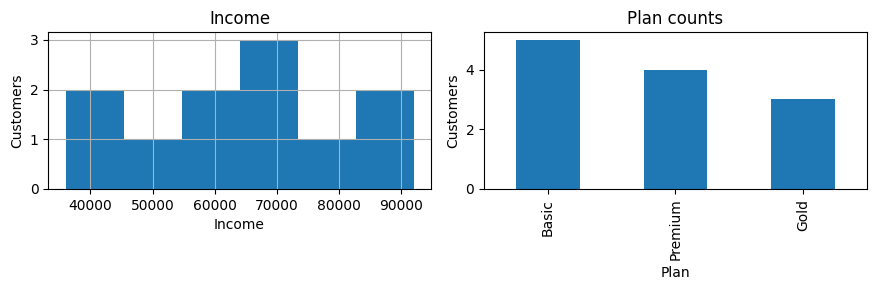

In [72]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
df['income'].hist(bins=6, ax=axes[0])
axes[0].set(title='Income', xlabel='Income', ylabel='Customers')
df['plan'].value_counts().plot.bar(ax=axes[1])
axes[1].set(title='Plan counts', xlabel='Plan', ylabel='Customers')
plt.tight_layout()
plt.show()

## 10. groupby and aggregation

Summarize repeated records, profile segments and create entity-level features. `agg()` reduces rows; `transform()` preserves row count.

### groupby().size() / count()

**Why for ML:** Count rows per category and compare missing-aware counts.

**Template:** `df.groupby("key").size(); df.groupby("key")["x"].count()`

**How to interpret:** `size` counts all rows; `count` counts non-null values in selected columns.

In [73]:
print('Customers per plan:', df.groupby('plan').size().to_dict())
print('Income non-null per plan:', df.groupby('plan')['income'].count().to_dict())

Customers per plan: {'Basic': 5, 'Gold': 3, 'Premium': 4}
Income non-null per plan: {'Basic': 5, 'Gold': 3, 'Premium': 3}


### groupby().agg()

**Why for ML:** Summarize multiple columns with custom aggregate names.

**Template:** `df.groupby("key").agg(mean_x=("x","mean"))`

**How to interpret:** For a binary 0/1 target, mean is the positive-class fraction.

In [74]:
plan_summary = df.groupby('plan', as_index=False).agg(
    customers=('customer_id','nunique'),
    avg_income=('income','mean'),
    churn_rate=('churned','mean'))
display(plan_summary.round(2))

,plan,customers,avg_income,churn_rate
0,Basic,5,57600.00,0.60
1,Gold,3,54333.33,0.33
2,Premium,3,88000.00,0.00


### groupby().transform()

**Why for ML:** Calculate group statistics while keeping one value per original row.

**Template:** `df.groupby("group")["x"].transform("mean")`

**How to interpret:** Target encoding and global group summaries must be cross-fitted or trained only on the training data.

In [75]:
tmp = df[['plan','income']].copy()
tmp['plan_mean_income'] = tmp.groupby('plan')['income'].transform('mean')
display(tmp.head())

,plan,income,plan_mean_income
0,Basic,45000.0,57600.0
1,Premium,80000.0,88000.0
2,Basic,61000.0,57600.0
3,Premium,NaN,88000.0
4,Basic,50000.0,57600.0


### groupby().filter()

**Why for ML:** Keep only groups satisfying an aggregate condition.

**Template:** `df.groupby("group").filter(lambda x: len(x) >= n)`

In [76]:
enough = df.groupby('plan').filter(lambda g: len(g) >= 4)
print('Retained plans:', enough['plan'].unique().tolist())

Retained plans: ['Basic', 'Premium']


### groupby().cumcount()

**Why for ML:** Number observations within each entity for behavioral features.

**Template:** `df.groupby("customer_id").cumcount() + 1`

In [77]:
ordered = orders.sort_values(['customer_id','order_date']).copy()
ordered['purchase_number'] = ordered.groupby('customer_id').cumcount() + 1
display(ordered[['customer_id','order_id','purchase_number']].head(8))

,customer_id,order_id,purchase_number
0,101,1,1
1,101,2,2
14,101,15,3
2,102,3,1
3,103,4,1
4,104,5,1
5,105,6,1
6,105,7,2


### groupby().shift()

**Why for ML:** Find prior purchases per customer without mixing customers.

**Template:** `df.groupby("id")["date"].shift(1)`

In [78]:
ordered['previous_order'] = ordered.groupby('customer_id')['order_date'].shift(1)
ordered['days_since_previous'] = (ordered['order_date']-ordered['previous_order']).dt.days
display(ordered[['customer_id','order_date','previous_order','days_since_previous']].head(8))

,customer_id,order_date,previous_order,days_since_previous
0,101,2025-07-01,NaT,NaN
1,101,2025-07-02,2025-07-01,1.0
14,101,2025-09-01,2025-07-02,61.0
2,102,2025-07-03,NaT,NaN
3,103,2025-07-10,NaT,NaN
4,104,2025-07-15,NaT,NaN
5,105,2025-07-20,NaT,NaN
6,105,2025-07-22,2025-07-20,2.0


### groupby().rank()

**Why for ML:** Rank products or purchases within each group.

**Template:** `df.groupby("customer_id")["quantity"].rank(ascending=False)`

In [79]:
ordered['quantity_rank'] = ordered.groupby('customer_id')['quantity'].rank(method='dense', ascending=False)
display(ordered[['customer_id','quantity','quantity_rank']].head(8))

,customer_id,quantity,quantity_rank
0,101,1,2.0
1,101,2,1.0
14,101,1,2.0
2,102,1,1.0
3,103,1,1.0
4,104,3,1.0
5,105,1,2.0
6,105,2,1.0


### groupby().apply() [advanced]

**Why for ML:** Handle complex group logic when built-in aggregations are insufficient.

**Template:** `df.groupby("key").apply(function)`

**How to interpret:** The equivalent custom `agg` shown here is usually simpler than `groupby.apply`.

In [80]:
# Prefer named agg and transform for standard cases; this is a demonstrative advanced option.
summary = orders.groupby('customer_id')['quantity'].agg(lambda s: s.max() - s.min())
print('Quantity range per customer:')
print(summary.head())

Quantity range per customer:
customer_id
101    1
102    0
103    0
104    0
105    1
Name: quantity, dtype: int64


## 11. Combine data from multiple sources

Correct joins are essential when assembling training datasets. Validate keys to prevent silent row multiplication.

### merge() — left / inner / outer joins

**Why for ML:** Combine orders with product catalog and customer attributes.

**Template:** `left.merge(right, on="id", how="left", validate="many_to_one")`

**How to interpret:** `validate="many_to_one"` fails if lookup product keys are unexpectedly duplicated.

In [81]:
order_items = orders.merge(products, on='product_id', how='left', validate='many_to_one')
order_items['sales'] = order_items['quantity'] * order_items['unit_price']
display(order_items.head(4))
print('Inner rows:', len(orders.merge(products, on='product_id', how='inner')))
print('Outer rows:', len(orders.merge(products, on='product_id', how='outer')))

,order_id,customer_id,product_id,quantity,order_date,category,unit_price,sales
0,1,101,P1,1,2025-07-01,Electronics,1200,1200
1,2,101,P3,2,2025-07-02,Electronics,2200,4400
2,3,102,P2,1,2025-07-03,Home,500,500
3,4,103,P2,1,2025-07-10,Home,500,500


Inner rows: 16
Outer rows: 16


### merge(indicator=True) / suffixes

**Why for ML:** Audit unmatched keys and ambiguous column names.

**Template:** `pd.merge(a, b, how="outer", indicator=True)`

**How to interpret:** Review left_only and right_only rows instead of silently dropping unmatched data.

In [82]:
left = pd.DataFrame({'id':[1,2,3], 'score':[10,20,30]})
right = pd.DataFrame({'id':[2,3,4], 'score':[200,300,400]})
audit = left.merge(right, on='id', how='outer', indicator=True, suffixes=('_old','_new'))
display(audit)

,id,score_old,score_new,_merge
0,1,10.0,NaN,left_only
1,2,20.0,200.0,both
2,3,30.0,300.0,both
3,4,NaN,400.0,right_only


### concat() — rows and columns

**Why for ML:** Stack equal-schema datasets or concatenate engineered feature blocks.

**Template:** `pd.concat([a,b], ignore_index=True)`

**How to interpret:** Column-wise concat aligns by index, not by a customer ID column.

In [83]:
q1 = pd.DataFrame({'id':[1,2], 'sales':[10,20]})
q2 = pd.DataFrame({'id':[3], 'sales':[30]})
combined = pd.concat([q1,q2], ignore_index=True)
display(combined)
print('Horizontal concatenation by index:')
display(pd.concat([q1[['id']], q1[['sales']]], axis=1))

,id,sales
0,1,10
1,2,20
2,3,30


Horizontal concatenation by index:


,id,sales
0,1,10
1,2,20


### join()

**Why for ML:** Join two tables using their indexes.

**Template:** `left.join(right, how="left")`

In [84]:
left = pd.DataFrame({'customer_id':[1,2], 'age':[20,35]}).set_index('customer_id')
right = pd.DataFrame({'customer_id':[1,2], 'spend':[100,300]}).set_index('customer_id')
display(left.join(right))

,age,spend
customer_id,,
1,20,100
2,35,300


### Series.map()

**Why for ML:** Map reference values or business rules without a full merge.

**Template:** `df["code"].map(mapping_dict)`

**How to interpret:** Ordinal numbers impose an ordering; only use this encoding when the order is meaningful.

In [85]:
risk_code = {'Basic': 1, 'Gold': 2, 'Premium': 3}
print(df['plan'].map(risk_code).head().tolist())

[1, 3, 1, 3, 1]


### merge_asof()

**Why for ML:** Match each event to the latest earlier reference record.

**Template:** `pd.merge_asof(events, rates, on="time", direction="backward")`

**How to interpret:** Backward matching uses information available at event time; nearest/forward may leak the future.

In [86]:
quotes = pd.DataFrame({'time':pd.to_datetime(['2025-01-01','2025-01-03']), 'price':[100,105]})
events = pd.DataFrame({'time':pd.to_datetime(['2025-01-02','2025-01-04']), 'volume':[3,5]})
matched = pd.merge_asof(events.sort_values('time'), quotes.sort_values('time'),
                        on='time', direction='backward')
display(matched)

,time,volume,price
0,2025-01-02,3,100
1,2025-01-04,5,105


## 12. Reshape tables for analysis

Switch between wide and long layouts, and summarize multi-dimensional observations.

### pivot()

**Why for ML:** Turn long records into wide columns when each index/column pair is unique.

**Template:** `df.pivot(index="id", columns="type", values="score")`

**How to interpret:** `pivot` fails if duplicate index-column combinations exist.

In [87]:
long = pd.DataFrame({'student':['A','A','B','B'],'exam':['Math','English','Math','English'], 'score':[80,75,70,90]})
wide = long.pivot(index='student', columns='exam', values='score')
display(wide)

exam,English,Math
student,,
A,75,80
B,90,70


### pivot_table()

**Why for ML:** Aggregate repeated index-column pairs.

**Template:** `pd.pivot_table(df, index="group", columns="label", values="x", aggfunc="mean")`

In [88]:
table = pd.pivot_table(df, index='plan', columns='churned', values='income', aggfunc='mean')
display(table.round(1))

churned,0,1
plan,,
Basic,54500.0,59666.7
Gold,63500.0,36000.0
Premium,88000.0,NaN


### melt()

**Why for ML:** Convert wide monthly/measurement columns to a tidy long format.

**Template:** `df.melt(id_vars=["id"], var_name="feature", value_name="value")`

In [89]:
wide_scores = pd.DataFrame({'id':[1,2], 'math':[70,80], 'science':[75,85]})
display(wide_scores.melt(id_vars='id', var_name='subject', value_name='score'))

,id,subject,score
0,1,math,70
1,2,math,80
2,1,science,75
3,2,science,85


### stack() / unstack()

**Why for ML:** Move levels between columns and index.

**Template:** `wide.stack(); series.unstack()`

**How to interpret:** With missing values, check the stacking behavior of your installed pandas version.

In [90]:
stacked = wide.stack()
print(stacked)
display(stacked.unstack())

student  exam   
A        English    75
         Math       80
B        English    90
         Math       70
dtype: int64


exam,English,Math
student,,
A,75,80
B,90,70


### explode()

**Why for ML:** Expand a list-valued field into one row per item.

**Template:** `df.explode("tags")`

In [91]:
users = pd.DataFrame({'user':['A','B'], 'tags':[['tech','music'],['sports']]})
display(users.explode('tags', ignore_index=True))

,user,tags
0,A,tech
1,A,music
2,B,sports


### transpose() / T

**Why for ML:** Swap row and column axes for quick viewing.

**Template:** `df.T`

**How to interpret:** Not a typical operation on the final ML feature matrix.

In [92]:
display(products.set_index('product_id').T)

product_id,P1,P2,P3,P4
category,Electronics,Home,Electronics,Sports
unit_price,1200,500,2200,750


## 13. Dates, times and rolling features

Many ML projects use transactions, sensors and events. **Temporal leakage** is one of the most damaging modelling errors.

### date_range() / Timestamp() / Timedelta()

**Why for ML:** Build a regular time axis or represent durations.

**Template:** `pd.date_range(start=..., periods=..., freq="D")`

In [93]:
dates = pd.date_range('2025-01-01', periods=5, freq='D')
print(dates)
print(pd.Timestamp('2025-01-05') + pd.Timedelta(days=7))

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05'], dtype='datetime64[ns]', freq='D')
2025-01-12 00:00:00


### dt.year / month / day / dayofweek / is_month_end

**Why for ML:** Extract calendar features from timestamps.

**Template:** `s.dt.month; s.dt.dayofweek`

In [94]:
tmp = orders[['order_date']].head(4).copy()
tmp['month'] = tmp['order_date'].dt.month
tmp['weekday'] = tmp['order_date'].dt.day_name()
tmp['weekend'] = tmp['order_date'].dt.dayofweek >= 5
display(tmp)

,order_date,month,weekday,weekend
0,2025-07-01,7,Tuesday,False
1,2025-07-02,7,Wednesday,False
2,2025-07-03,7,Thursday,False
3,2025-07-10,7,Thursday,False


### dt.days / to_timedelta()

**Why for ML:** Turn durations into numeric features.

**Template:** `(end - start).dt.days`

In [95]:
start = pd.to_datetime(pd.Series(['2025-01-01','2025-02-01']))
end = start + pd.to_timedelta([7,14], unit='D')
print((end - start).dt.days.tolist())

[7, 14]


### dt.floor() / normalize()

**Why for ML:** Bucket event timestamps into common time periods.

**Template:** `s.dt.floor("h"); s.dt.normalize()`

In [96]:
timestamps = pd.to_datetime(pd.Series(['2025-01-01 10:35:00','2025-01-01 12:20:00']))
print('Hour:', timestamps.dt.floor('h').tolist())
print('Midnight:', timestamps.dt.normalize().tolist())

Hour: [Timestamp('2025-01-01 10:00:00'), Timestamp('2025-01-01 12:00:00')]
Midnight: [Timestamp('2025-01-01 00:00:00'), Timestamp('2025-01-01 00:00:00')]


### tz_localize() / tz_convert()

**Why for ML:** Work safely with time zones in operational ML data.

**Template:** `s.dt.tz_localize("UTC").dt.tz_convert("Asia/Kolkata")`

**How to interpret:** Localize naive timestamps only when you know their original timezone.

In [97]:
utc_time = pd.Series(pd.to_datetime(['2025-01-01 06:00:00'])).dt.tz_localize('UTC')
india_time = utc_time.dt.tz_convert('Asia/Kolkata')
print('UTC:', utc_time.iloc[0], '| IST:', india_time.iloc[0])

UTC: 2025-01-01 06:00:00+00:00 | IST: 2025-01-01 11:30:00+05:30


### resample()

**Why for ML:** Aggregate events into daily/monthly time series.

**Template:** `df.set_index("date").resample("MS").sum()`

**How to interpret:** `MS` means month start. A missing month in the date range contributes zero after `sum()`.

In [98]:
daily_sales = order_items.set_index('order_date')['sales'].sort_index().resample('MS').sum()
print(daily_sales)

order_date
2025-07-01    14600
2025-08-01     9050
2025-09-01     2000
Freq: MS, Name: sales, dtype: int64


### rolling()

**Why for ML:** Build moving averages and window statistics.

**Template:** `s.rolling(window=3, min_periods=1).mean()`

**How to interpret:** For forecasting, use `shift(1)` before rolling if predicting the current timestamp.

In [99]:
signal = pd.Series([10,12,20,18,15,25])
print('Rolling mean:', signal.rolling(window=3, min_periods=1).mean().round(1).tolist())

Rolling mean: [10.0, 11.0, 14.0, 16.7, 17.7, 19.3]


### expanding() / ewm()

**Why for ML:** Compute cumulative and exponentially weighted trends.

**Template:** `s.expanding().mean(); s.ewm(span=3).mean()`

**How to interpret:** Exponential smoothing weights recent history more heavily.

In [100]:
print('Expanding mean:', signal.expanding().mean().round(2).tolist())
print('EWM:', signal.ewm(span=3, adjust=False).mean().round(2).tolist())

Expanding mean: [10.0, 11.0, 14.0, 15.0, 15.0, 16.67]
EWM: [10.0, 11.0, 15.5, 16.75, 15.88, 20.44]


### asfreq() / ffill() / bfill()

**Why for ML:** Reindex to regular time frequency and fill time gaps appropriately.

**Template:** `series.asfreq("D").ffill()`

**How to interpret:** `bfill` can use future information. Prefer `ffill` only when it matches the real-world process.

In [101]:
sparse = pd.Series([100,120], index=pd.to_datetime(['2025-01-01','2025-01-04']))
regular = sparse.asfreq('D')
print('Before fill:', regular.tolist())
print('Forward fill:', regular.ffill().tolist())
print('Backward fill:', regular.bfill().tolist())

Before fill: [100.0, nan, nan, 120.0]
Forward fill: [100.0, 100.0, 100.0, 120.0]
Backward fill: [100.0, 120.0, 120.0, 120.0]


### interpolate()

**Why for ML:** Estimate missing values along an ordered measurement series.

**Template:** `s.interpolate(method="linear")`

**How to interpret:** Standard interpolation uses later observations; inappropriate for many real-time forecasts.

In [102]:
measurements = pd.Series([10.0, np.nan, np.nan, 16.0])
print(measurements.interpolate().tolist())

[10.0, 12.0, 14.0, 16.0]


### Temporal lag + rolling example

**Why for ML:** Build a correct historical feature for time-series prediction.

**Template:** `s.shift(1).rolling(3).mean()`

**How to interpret:** At time t, the feature uses t−1, t−2 and t−3; it does not use the current outcome.

In [103]:
past_3_avg = signal.shift(1).rolling(window=3, min_periods=3).mean()
print(pd.DataFrame({'today':signal, 'past_3_avg':past_3_avg}))

   today  past_3_avg
0     10         NaN
1     12         NaN
2     20         NaN
3     18   14.000000
4     15   16.666667
5     25   17.666667


## 14. Encoding and practical feature engineering

Pandas makes it easy to construct model-ready features, but preprocessing learned from data must be fitted on training records alone.

### get_dummies() — one-hot encoding

**Why for ML:** Convert unordered categories into numerical indicator features.

**Template:** `pd.get_dummies(df, columns=["category"], dtype=int)`

**How to interpret:** Encode validation/test with the *same training columns*. See section 16.

In [104]:
small = df[['plan']].head(6)
encoded = pd.get_dummies(small, columns=['plan'], dtype=int)
display(encoded)

,plan_Basic,plan_Gold,plan_Premium
0,1,0,0
1,0,0,1
2,1,0,0
3,0,0,1
4,1,0,0
5,0,1,0


### factorize()

**Why for ML:** Assign integer IDs to distinct category labels for IDs/analysis.

**Template:** `codes, labels = pd.factorize(s)`

**How to interpret:** Factorized codes are arbitrary, not meaningful numeric distances. For nominal model features, prefer one-hot encoding.

In [105]:
codes, labels = pd.factorize(df['plan'])
print('Codes:', codes[:8])
print('Code-to-name:', list(labels))

Codes: [0 1 0 1 0 2 2 0]
Code-to-name: ['Basic', 'Premium', 'Gold']


### astype("category") / cat.categories / cat.codes

**Why for ML:** Store fixed categories efficiently and inspect encoded category IDs.

**Template:** `s.astype("category").cat.codes`

**How to interpret:** Category codes are not inherently ordinal.

In [106]:
plan_cat = df['plan'].astype('category')
print('Categories:', plan_cat.cat.categories.tolist())
print('Codes:', plan_cat.cat.codes.head().tolist())

Categories: ['Basic', 'Gold', 'Premium']
Codes: [0, 2, 0, 2, 0]


### pd.Categorical() — ordered labels

**Why for ML:** Represent genuinely ordered bands.

**Template:** `pd.Categorical(values, categories=[...], ordered=True)`

In [107]:
levels = pd.Categorical(['Low','High','Medium','Low'],
                        categories=['Low','Medium','High'], ordered=True)
print(pd.Series(levels).sort_values().tolist())

['Low', 'Low', 'Medium', 'High']


### assign() / lambda

**Why for ML:** Create new columns in a readable, chainable manner.

**Template:** `df.assign(new_col=lambda d: d["x"] * 2)`

In [108]:
features = order_items.assign(
    order_value=lambda d: d['quantity']*d['unit_price'],
    high_value=lambda d: (d['quantity']*d['unit_price'] >= 2000).astype(int))
display(features[['quantity','unit_price','order_value','high_value']].head())

,quantity,unit_price,order_value,high_value
0,1,1200,1200,0
1,2,2200,4400,1
2,1,500,500,0
3,1,500,500,0
4,3,1200,3600,1


### np.where() / np.select() [NumPy helpers]

**Why for ML:** Create conditional numeric or multi-class features.

**Template:** `np.where(condition, yes, no)`

**How to interpret:** Missing income falls into `Low/Unknown` in this simplified demonstration; real pipelines should separate missing.

In [109]:
income = df['income']
label = np.where(income >= 70000, 'High', 'Other')
category = np.select([income >= 80000, income >= 50000], ['High','Medium'], default='Low/Unknown')
print(pd.DataFrame({'income':income,'binary':label,'band':category}).head(7))

    income binary         band
0  45000.0  Other  Low/Unknown
1  80000.0   High         High
2  61000.0  Other       Medium
3      NaN  Other  Low/Unknown
4  50000.0  Other       Medium
5  72000.0   High       Medium
6  55000.0  Other       Medium


### map() / replace() for business rules

**Why for ML:** Translate known raw categories into engineered groups.

**Template:** `s.map({"raw":"standardized"})`

**How to interpret:** Unmapped categories become missing with `map`.

In [110]:
city_group = df['city'].str.title().map({'Mumbai':'West','Pune':'West','Delhi':'North','Bengaluru':'South'})
print(city_group.value_counts(dropna=False))

city
West     7
North    3
NaN      1
South    1
Name: count, dtype: int64


### groupby aggregation → merge back

**Why for ML:** Create historical customer-level features from transactions.

**Template:** `group_features = orders.groupby("id").agg(...); users.merge(...)`

**How to interpret:** The example aggregates **all** toy transactions; real prediction features must be cut off strictly before each prediction time.

In [111]:
customer_order_features = order_items.groupby('customer_id', as_index=False).agg(
    order_count=('order_id','nunique'),
    total_spend=('sales','sum'),
    avg_order_value=('sales','mean'))
customers_with_orders = clean.merge(customer_order_features, on='customer_id', how='left', validate='one_to_one')
display(customers_with_orders[['customer_id','order_count','total_spend']].head(7))

,customer_id,order_count,total_spend
0,101,3,6100
1,102,1,500
2,103,1,500
3,104,1,3600
4,105,2,3200
5,106,2,2700
6,107,1,1500


### pd.to_numeric + log1p() [NumPy helper]

**Why for ML:** Reduce skew in positive numeric features.

**Template:** `np.log1p(pd.to_numeric(s, errors="coerce"))`

**How to interpret:** `log1p(x)` handles zero and is intended for x > −1.

In [112]:
amounts = pd.Series([0, 100, 1000, 10000])
print('Raw:', amounts.tolist())
print('log1p:', np.log1p(amounts).round(2).tolist())

Raw: [0, 100, 1000, 10000]
log1p: [0.0, 4.62, 6.91, 9.21]


### Feature selection with select_dtypes() and drop()

**Why for ML:** Assemble numeric inputs while excluding target and identifiers.

**Template:** `X = df.drop(columns=["target", "id"])`

**How to interpret:** Identifiers often cause memorization; also exclude any post-outcome data.

In [113]:
numeric_candidates = clean.select_dtypes(include='number').drop(columns=['customer_id','churned'], errors='ignore')
print('Candidate numeric features:', numeric_candidates.columns.tolist())
print('Target excluded?', 'churned' not in numeric_candidates.columns)

Candidate numeric features: ['age', 'income', 'age_filled', 'income_missing']
Target excluded? True


## 15. Validation, quality checks and efficiency

Use explicit checks before training or exporting. Silent data errors often harm models more than parameter choices.

### any() / all() / equals()

**Why for ML:** Check conditions and compare outputs.

**Template:** `condition.any(); condition.all(); a.equals(b)`

In [114]:
print('Any income missing?', df['income'].isna().any())
print('All orders positive?', (orders['quantity'] > 0).all())
print('Copy equals original?', df.equals(df.copy()))

Any income missing? True
All orders positive? True
Copy equals original? True


### nunique() / is_unique

**Why for ML:** Validate primary-key uniqueness and categorical cardinality.

**Template:** `df["id"].is_unique`

In [115]:
print('Customer key unique in raw?', df['customer_id'].is_unique)
print('Customer key unique after dedup?', clean['customer_id'].is_unique)
print('Number of plans:', clean['plan'].nunique())

Customer key unique in raw? False
Customer key unique after dedup? True
Number of plans: 3


### duplicated subset + assert

**Why for ML:** Fail early when a join would duplicate records.

**Template:** `assert not table["id"].duplicated().any()`

In [116]:
assert clean['customer_id'].is_unique, 'Customer IDs must be unique'
assert (orders['quantity'] > 0).all(), 'Quantities must be positive'
print('Validation checks passed')

Validation checks passed


### pd.testing.assert_frame_equal()

**Why for ML:** Check whether transformation results match expectations.

**Template:** `pd.testing.assert_frame_equal(actual, expected)`

In [117]:
a = pd.DataFrame({'x':[1,2]})
b = pd.DataFrame({'x':[1,2]})
pd.testing.assert_frame_equal(a,b)
print('Frames match')

Frames match


### pipe() — reusable transformations

**Why for ML:** Compose simple, testable cleaning operations.

**Template:** `df.pipe(clean_function)`

In [118]:
def standardize_city(frame):
    result = frame.copy()
    result['city'] = result['city'].astype('string').str.strip().str.title()
    return result

standardized = df.pipe(standardize_city)
print(standardized['city'].value_counts(dropna=False))

city
Mumbai       4
Delhi        3
Pune         3
<NA>         1
Bengaluru    1
Name: count, dtype: Int64


### apply() vs vectorized operations

**Why for ML:** Prefer faster readable column operations to row-wise Python loops.

**Template:** `df["x"] * df["y"]  # preferred`

**How to interpret:** `apply(axis=1)` is often slower and rarely needed for elementary calculations.

In [119]:
fast = orders['quantity'] * 2
slower = orders['quantity'].apply(lambda n: n * 2)
print('Same result?', fast.equals(slower))

Same result? True


### memory optimization: category / downcast

**Why for ML:** Reduce memory for large repetitive text and numeric columns.

**Template:** `s.astype("category"); pd.to_numeric(s, downcast="integer")`

**How to interpret:** Check min/max range before downcasting numeric features.

In [120]:
plans = pd.Series(['Basic','Gold','Basic','Gold'] * 1000)
print('String KiB:', round(plans.memory_usage(deep=True)/1024, 1))
print('Categorical KiB:', round(plans.astype('category').memory_usage(deep=True)/1024, 1))
small_ints = pd.to_numeric(pd.Series([1,2,3]), downcast='integer')
print('Downcast dtype:', small_ints.dtype)

String KiB: 209.1
Categorical KiB: 4.2
Downcast dtype: int8


### Pandas 3.x Copy-on-Write-safe assignment

**Why for ML:** Change a DataFrame through a single indexing operation.

**Template:** `df.loc[mask, "column"] = value`

**How to interpret:** Chained assignment will not update the intended original table under Pandas 3.x Copy-on-Write.

In [121]:
demo = pd.DataFrame({'age':[17,25,15]})
demo.loc[demo['age'] < 18, 'age_group'] = 'Minor'
demo['age_group'] = demo['age_group'].fillna('Adult')
display(demo)

,age,age_group
0,17,Minor
1,25,Adult
2,15,Minor


## 16. End-to-end: train/test-ready data without leakage

Realistic example: generate customer data, intentionally add missing values and categories, split first, fit Pandas transformations only on training data, align test features and train a simple classifier. This is a teaching workflow; for production, use `Pipeline` and `ColumnTransformer` from scikit-learn.

In [122]:
# Generate a larger, reproducible synthetic customer dataset (no external data needed).
rng = np.random.default_rng(42)
n = 350
ml_df = pd.DataFrame({
    'customer_id': np.arange(1001, 1001+n),
    'age': rng.integers(18, 70, n).astype(float),
    'monthly_spend': np.clip(rng.normal(3500, 1200, n), 100, None),
    'visits': rng.poisson(5, n),
    'city': rng.choice(['Mumbai','Pune','Delhi','Bengaluru'], n),
    'membership': rng.choice(['Basic','Gold','Premium'], n, p=[0.5,0.3,0.2])
})
# A probabilistic synthetic target, not a real-world causal relationship.
logit = -0.8 + 0.025*(ml_df['age']-40) + 0.00025*(ml_df['monthly_spend']-3500) - 0.2*ml_df['visits']
prob = 1 / (1 + np.exp(-logit))
ml_df['churned'] = rng.binomial(1, prob)
ml_df.loc[rng.choice(n, size=25, replace=False), 'age'] = np.nan
ml_df.loc[rng.choice(n, size=20, replace=False), 'monthly_spend'] = np.nan
print('Dataset:', ml_df.shape, '| churn rate:', round(ml_df['churned'].mean(), 3))
display(ml_df.head())

Dataset: (350, 7) | churn rate: 0.166


,customer_id,age,monthly_spend,visits,city,membership,churned
0,1001,22.0,2954.019824,4,Bengaluru,Gold,0
1,1002,58.0,2029.273083,4,Mumbai,Gold,0
2,1003,52.0,1966.474911,3,Pune,Gold,0
3,1004,40.0,3707.105501,4,Bengaluru,Basic,1
4,1005,40.0,5394.909508,6,Delhi,Basic,0


### Step 1 — choose X/y and split FIRST

**Why for ML:** Set aside untouched test rows before learning imputation medians or encoding.

**Template:** `train_test_split(X, y, stratify=y, random_state=42)`

**How to interpret:** Use a chronological split rather than random splitting for genuine forecasting problems.

In [123]:
from sklearn.model_selection import train_test_split
X = ml_df.drop(columns=['customer_id','churned'])
y = ml_df['churned']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train churn rate:', y_train.mean().round(3), '| Test churn rate:', y_test.mean().round(3))

Train: (280, 5) | Test: (70, 5)
Train churn rate: 0.164 | Test churn rate: 0.171


### Step 2 — fit median values on TRAIN ONLY

**Why for ML:** Avoid using validation/test distributions to decide imputation values.

**Template:** `train_medians = X_train[numeric_cols].median()`

In [124]:
numerical = ['age','monthly_spend','visits']
train_medians = X_train[numerical].median()
print('Training-only medians:', train_medians.to_dict())
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()
X_train_clean[numerical] = X_train_clean[numerical].fillna(train_medians)
X_test_clean[numerical] = X_test_clean[numerical].fillna(train_medians)
print('Missing train:', X_train_clean[numerical].isna().sum().sum())
print('Missing test:', X_test_clean[numerical].isna().sum().sum())

Training-only medians: {'age': 42.5, 'monthly_spend': 3441.5379176838583, 'visits': 5.0}
Missing train: 0
Missing test: 0


### Step 3 — one-hot encode and align to train columns

**Why for ML:** Create consistent feature dimensions for model.fit and model.predict.

**Template:** `pd.get_dummies(...).reindex(columns=train_cols, fill_value=0)`

**How to interpret:** An unseen category at prediction time becomes all zeros for that feature group here; consider unknown-category handling in a production encoder.

In [125]:
X_train_ready = pd.get_dummies(X_train_clean, columns=['city','membership'], dtype=int)
X_test_ready = pd.get_dummies(X_test_clean, columns=['city','membership'], dtype=int)
X_test_ready = X_test_ready.reindex(columns=X_train_ready.columns, fill_value=0)
print('Train columns:', X_train_ready.columns.tolist())
print('Same columns and order?', X_train_ready.columns.equals(X_test_ready.columns))
assert not X_train_ready.isna().any().any()
assert not X_test_ready.isna().any().any()

Train columns: ['age', 'monthly_spend', 'visits', 'city_Bengaluru', 'city_Delhi', 'city_Mumbai', 'city_Pune', 'membership_Basic', 'membership_Gold', 'membership_Premium']
Same columns and order? True


### Step 4 — fit, predict and evaluate a simple classifier

**Why for ML:** Confirm the Pandas output is accepted by a model.

**Template:** `model.fit(X_train_ready, y_train); model.predict(X_test_ready)`

**How to interpret:** Scikit-learn owns model fitting/scaling here; Pandas owns data processing. Accuracy alone is insufficient for imbalanced churn labels.

In [126]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# Scale with statistics learned only from training rows (for a stable logistic regression demo).
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train_ready)
test_scaled = scaler.transform(X_test_ready)
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(train_scaled, y_train)
preds = model.predict(test_scaled)
print('Test accuracy:', round(accuracy_score(y_test, preds), 3))
print(classification_report(y_test, preds, zero_division=0))

Test accuracy: 0.843
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        58
           1       1.00      0.08      0.15        12

    accuracy                           0.84        70
   macro avg       0.92      0.54      0.53        70
weighted avg       0.87      0.84      0.78        70



### Step 5 — prepare a single new example

**Why for ML:** Reuse the same training medians and feature list at inference.

**Template:** `new = pd.get_dummies(new,...).reindex(columns=train_cols, fill_value=0)`

**How to interpret:** The same preprocessing steps, fitted statistics and column order must be reused in deployment.

In [127]:
new_customer = pd.DataFrame({'age':[31], 'monthly_spend':[np.nan], 'visits':[2],
                             'city':['Mumbai'], 'membership':['Gold']})
new_customer[numerical] = new_customer[numerical].fillna(train_medians)
new_encoded = pd.get_dummies(new_customer, columns=['city','membership'], dtype=int)
new_encoded = new_encoded.reindex(columns=X_train_ready.columns, fill_value=0)
new_pred = model.predict(scaler.transform(new_encoded))
new_prob = model.predict_proba(scaler.transform(new_encoded))[:,1]
print('Predicted churn class:', int(new_pred[0]))
print('Predicted churn probability:', round(float(new_prob[0]), 3))

Predicted churn class: 0
Predicted churn probability: 0.276


### Which Pandas operations are *not* a replacement for an ML pipeline?

- `pd.get_dummies()` is convenient for teaching, but a fitted `OneHotEncoder(handle_unknown="ignore")` inside a `ColumnTransformer` handles unseen categories more explicitly.
- `.fillna(train_median)` is correct only if the median is learned on **training data** and reused unchanged; production code usually uses `SimpleImputer` in a `Pipeline`.
- Standardization is not a Pandas method; fit `StandardScaler` on training features only.
- Aggregations involving events after the prediction timestamp or target values can leak future outcomes, even if you never use the target column directly.
- For cross-validation and `GridSearchCV`, all fitted preprocessing should live **inside** the pipeline so each CV fold learns statistics only from its own training fold.

**Pandas 3 note:** string inference and Copy-on-Write differ from older releases. Our code uses `.loc` assignment and does not assume strings always have `object` dtype.

## 17. Classroom exercises

Attempt each exercise first; scroll to the answer key after completing them. Work with the original `df`, `orders`, and `products` unless otherwise noted.

| # | Exercise | Expected result / hint |
|---:|---|---|
| 1 | Display only `customer_id`, `city`, `income` for first 5 rows. | Column selection + `head` |
| 2 | Count missing values in every column. | `isna` + `sum` |
| 3 | Convert `age` to numbers; invalid values should become missing. | `to_numeric` |
| 4 | Standardize city names to title case. | `str.title` |
| 5 | Remove duplicate customer IDs. | `drop_duplicates` |
| 6 | Find the most frequent subscription plan. | `value_counts` |
| 7 | Find customers with income greater than 60,000 AND plan Gold. | Boolean mask |
| 8 | Calculate the mean income by plan, ignoring missing values. | `groupby` |
| 9 | Create one-hot variables for subscription plan. | `get_dummies` |
| 10 | Merge `orders` with `products` to compute sales per order. | `merge` + multiplication |
| 11 | Calculate total spend per customer from the merged table. | `groupby` + `sum` |
| 12 | Create monthly sales totals. | `resample` |
| 13 | Find each customer's previous order date. | `sort_values` + `groupby.shift` |
| 14 | Create age groups using bins 0–25, 25–40, 40–60, 60+. | `cut` |
| 15 | Build a target summary by plan: count and churn rate. | named `agg` |
| 16 | Verify every product has a unique product ID before joining. | `is_unique` / `assert` |
| 17 | Explain why imputing before train/test split causes leakage. | Conceptual explanation |
| 18 | Explain why a full-customer lifetime spend feature is invalid for predicting earlier churn. | Temporal leakage |

### Exercise answer key — runnable solutions

In [128]:
# 1: Columns + head
print('1')
display(df[['customer_id','city','income']].head(5))

# 2: Null counts
print('2')
print(df.isna().sum())

# 3: Convert age
age_numeric = pd.to_numeric(df['age'], errors='coerce')
print('3:', age_numeric.head(7).tolist())

# 4: City standardization
cities_fixed = df['city'].astype('string').str.strip().str.title()
print('4:', cities_fixed.value_counts(dropna=False).to_dict())

# 5: Deduplicate
unique_df = df.drop_duplicates('customer_id')
print('5:', len(unique_df), 'rows')

# 6: Most common plan
print('6:', df['plan'].value_counts().idxmax())

# 7: Filter
print('7')
display(df.loc[(df['income'] > 60000) & (df['plan']=='Gold'), ['customer_id','income','plan']])

# 8: Group mean
print('8')
print(df.groupby('plan')['income'].mean().round(2))

# 9: Encode
print('9')
display(pd.get_dummies(df[['plan']], dtype=int).head())

1


,customer_id,city,income
0,101,Mumbai,45000.0
1,102,delhi,80000.0
2,103,Mumbai,61000.0
3,104,Pune,NaN
4,105,None,50000.0


2
customer_id    0
name           0
city           1
age            1
income         1
plan           0
signup_date    0
churned        0
dtype: int64
3: [25.0, 38.0, nan, 42.0, nan, 30.0, 27.0]
4: {'Mumbai': 4, 'Delhi': 3, 'Pune': 3, <NA>: 1, 'Bengaluru': 1}
5: 11 rows
6: Basic
7


,customer_id,income,plan
5,106,72000.0,Gold


8
plan
Basic      57600.00
Gold       54333.33
Premium    88000.00
Name: income, dtype: float64
9


,plan_Basic,plan_Gold,plan_Premium
0,1,0,0
1,0,0,1
2,1,0,0
3,0,0,1
4,1,0,0


In [129]:
# 10: Merge + sales
sales_df = orders.merge(products, on='product_id', how='left', validate='many_to_one')
sales_df['sales'] = sales_df['quantity'] * sales_df['unit_price']
print('10')
display(sales_df.head())

# 11: Spend by customer
print('11')
print(sales_df.groupby('customer_id')['sales'].sum().head())

# 12: Monthly sales
print('12')
print(sales_df.set_index('order_date')['sales'].resample('MS').sum())

# 13: Previous order
sorted_sales = sales_df.sort_values(['customer_id','order_date']).copy()
sorted_sales['previous_date'] = sorted_sales.groupby('customer_id')['order_date'].shift(1)
print('13')
display(sorted_sales[['customer_id','order_date','previous_date']].head())

# 14: Bins
print('14')
print(pd.cut(age_numeric, bins=[0,25,40,60,np.inf],
             labels=['0-25','26-40','41-60','60+']).value_counts(dropna=False))

# 15: Target summary
print('15')
print(df.groupby('plan').agg(count=('customer_id','size'), churn_rate=('churned','mean')))

# 16: Unique product IDs
assert products['product_id'].is_unique
print('16: Unique product IDs — passed')

10


,order_id,customer_id,product_id,quantity,order_date,category,unit_price,sales
0,1,101,P1,1,2025-07-01,Electronics,1200,1200
1,2,101,P3,2,2025-07-02,Electronics,2200,4400
2,3,102,P2,1,2025-07-03,Home,500,500
3,4,103,P2,1,2025-07-10,Home,500,500
4,5,104,P1,3,2025-07-15,Electronics,1200,3600


11
customer_id
101    6100
102     500
103     500
104    3600
105    3200
Name: sales, dtype: int64
12
order_date
2025-07-01    14600
2025-08-01     9050
2025-09-01     2000
Freq: MS, Name: sales, dtype: int64
13


,customer_id,order_date,previous_date
0,101,2025-07-01,NaT
1,101,2025-07-02,2025-07-01
14,101,2025-09-01,2025-07-02
2,102,2025-07-03,NaT
3,103,2025-07-10,NaT


14
age
26-40    5
41-60    3
0-25     2
NaN      2
60+      0
Name: count, dtype: int64
15
         count  churn_rate
plan                      
Basic        5    0.600000
Gold         3    0.333333
Premium      4    0.000000
16: Unique product IDs — passed


**17. Leakage answer:** If an income median is estimated using the test rows, information from test data affects how train features are transformed. This gives an overly optimistic model-selection/evaluation process. Split first, compute the median only on training data, and reuse it.

**18. Temporal leakage answer:** Total lifetime spend can contain purchases made **after** the date when a prediction was supposed to be produced. For historical training rows, calculate spend only up to each row's prediction cutoff date.

## 18. Quick-reference index and official resources

Use this as a navigation and revision checklist, from basic reading and cleaning to advanced, leakage-aware feature preparation.

### Lesson index (functions and applied patterns)

001. pd.Series()
002. pd.DataFrame()
003. DataFrame.from_records() / to_dict()
004. copy()
005. index / columns / axes
006. to_csv() / read_csv()
007. read_csv(usecols=, dtype=, na_values=)
008. read_csv(parse_dates=, nrows=)
009. read_csv(chunksize=)
010. to_excel() / read_excel()
011. to_json() / read_json()
012. read_sql_query() / to_sql()
013. read_parquet() / to_parquet() [optional]
014. head() / tail() / sample()
015. shape / size / empty
016. dtypes / info()
017. describe() / describe(include="all")
018. select_dtypes()
019. nunique() / unique()
020. value_counts() / normalize=True
021. isna() / notna() / sum()
022. duplicated()
023. memory_usage()
024. Single and multiple column selection
025. loc[] — label-based selection
026. iloc[] — position-based selection
027. at[] / iat[] — scalar access
028. Boolean masks: &, | and ~
029. isin() / between()
030. query()
031. filter() / get()
032. rename() / drop()
033. set_index() / reset_index()
034. where() / mask()
035. to_numeric(errors="coerce")
036. to_datetime(errors="coerce")
037. astype() / convert_dtypes()
038. fillna() — fixed / median / mode
039. groupby().transform() — group median fill
040. dropna()
041. drop_duplicates()
042. replace()
043. combine_first()
044. isna().astype(int) — missing indicator
045. clip()
046. quantile() / IQR diagnostics
047. str.strip() / lower() / upper() / title()
048. str.contains() / startswith() / endswith()
049. str.replace()
050. str.split() / str.get()
051. str.extract()
052. str.len() / str.count()
053. str.get_dummies()
054. sort_values() / sort_index()
055. nlargest() / nsmallest()
056. rank()
057. round() / abs()
058. pd.cut()
059. pd.qcut()
060. diff() / pct_change()
061. shift() / cumsum() / cummax()
062. sum(), count(), mean(), median(), min(), max()
063. std() / var() / sem()
064. quantile() / median() / mode()
065. skew() / kurt()
066. corr() / cov()
067. corrwith()
068. idxmax() / idxmin()
069. pd.crosstab()
070. plot() / hist() — quick Pandas visualization
071. groupby().size() / count()
072. groupby().agg()
073. groupby().transform()
074. groupby().filter()
075. groupby().cumcount()
076. groupby().shift()
077. groupby().rank()
078. groupby().apply() [advanced]
079. merge() — left / inner / outer joins
080. merge(indicator=True) / suffixes
081. concat() — rows and columns
082. join()
083. Series.map()
084. merge_asof()
085. pivot()
086. pivot_table()
087. melt()
088. stack() / unstack()
089. explode()
090. transpose() / T
091. date_range() / Timestamp() / Timedelta()
092. dt.year / month / day / dayofweek / is_month_end
093. dt.days / to_timedelta()
094. dt.floor() / normalize()
095. tz_localize() / tz_convert()
096. resample()
097. rolling()
098. expanding() / ewm()
099. asfreq() / ffill() / bfill()
100. interpolate()
101. Temporal lag + rolling example
102. get_dummies() — one-hot encoding
103. factorize()
104. astype("category") / cat.categories / cat.codes
105. pd.Categorical() — ordered labels
106. assign() / lambda
107. np.where() / np.select() [NumPy helpers]
108. map() / replace() for business rules
109. groupby aggregation → merge back
110. pd.to_numeric + log1p() [NumPy helper]
111. Feature selection with select_dtypes() and drop()
112. any() / all() / equals()
113. nunique() / is_unique
114. duplicated subset + assert
115. pd.testing.assert_frame_equal()
116. pipe() — reusable transformations
117. apply() vs vectorized operations
118. memory optimization: category / downcast
119. Pandas 3.x Copy-on-Write-safe assignment
120. Step 1 — choose X/y and split FIRST
121. Step 2 — fit median values on TRAIN ONLY
122. Step 3 — one-hot encode and align to train columns
123. Step 4 — fit, predict and evaluate a simple classifier
124. Step 5 — prepare a single new example

### Pandas documentation and version notes

- [Pandas User Guide](https://pandas.pydata.org/docs/user_guide/index.html) — official conceptual guidance.
- [Pandas API reference](https://pandas.pydata.org/docs/reference/index.html) — function arguments and examples.
- [Pandas 3.0 release notes](https://pandas.pydata.org/docs/whatsnew/v3.0.0.html) — changed defaults and new string handling.
- [Copy-on-Write guide](https://pandas.pydata.org/docs/user_guide/copy_on_write.html) — prefer direct `.loc` assignment.
- [Pandas string migration guide](https://pandas.pydata.org/docs/user_guide/migration-3-strings.html) — do not assume all text features are `object`.

**Instructor suggestion:** Have students run sections 1–6 first, complete exercises 1–8, then revisit sections 10–16 while building a supervised ML capstone. For students who finish early, ask them to add input validation and explain any potential leakage introduced by their own features.